In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# German Traffic Sign Recognition with a CNN

**Image classification · leakage-aware validation · error analysis**

This notebook builds an end-to-end image-classification pipeline for the **German Traffic Sign Recognition Benchmark (GTSRB)**. The objective is not only to train a convolutional neural network (CNN), but also to make the evaluation process understandable and defensible.

> **Core modeling decision:** training images are grouped by the physical-sign track encoded in the filename. A track is assigned entirely to either training or validation, so highly related frames of the same sign do not appear on both sides of the split.

## Project at a glance

| Stage | What this notebook does | Why it matters |
|---|---|---|
| Data understanding | Inspect metadata, image counts, and class frequencies | Understand the dataset before modeling |
| Validation design | `StratifiedGroupKFold` with a track identifier | Reduce optimistic validation caused by correlated frames |
| Preprocessing | Read images, crop the annotated region of interest (ROI), resize, normalize | Give every image a consistent representation |
| Augmentation | Small rotations, shifts, zoom, and shear on training images only | Add limited variation during training |
| Modeling | CNN with convolution, pooling, dropout, and a 43-class softmax output | Learn visual patterns for traffic-sign classification |
| Evaluation | Accuracy, macro precision/recall/F1, per-class report, confusion matrix, error examples | Understand both overall performance and weak classes |
| Final test | Evaluate once on the supplied `Test.csv` images | Keep final evaluation separate from model selection |

### Pipeline

`Metadata → Exploratory checks → Track-aware split → Image preprocessing → Augmentation → CNN training → Validation diagnostics → Official test evaluation`



## 1. Environment and dataset setup

The notebook is written to run in Kaggle with the GTSRB dataset attached as an input. It first checks the configured location, then tries to find `Train.csv` under `/kaggle/input`. If you run outside Kaggle, set `DATA_DIR` to the folder that contains `Train.csv` and `Test.csv`.

Expected files include:

- `Train.csv` — training image paths, class IDs, and ROI coordinates
- `Test.csv` — official test image paths, class IDs, and ROI coordinates
- The image files referenced by the `Path` column

The code uses a fixed random seed to make the split and training setup more reproducible. Exact GPU training results can still vary by environment.

In [1]:
import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from tensorflow import keras
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Conv2D, MaxPool2D, Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tqdm.auto import tqdm

SEED = 50
IMG_SIZE = 30
NUM_CLASSES = 43
BATCH_SIZE = 128
LEARNING_RATE = 0.00110  # selected configuration from an earlier tuning run

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)



In [2]:
BASE_PATH = '/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign'

train_df = pd.read_csv(os.path.join(BASE_PATH, 'Train.csv'))

# First filename component = track ID
'''train_df['track_id'] = (
    train_df['ClassId'].astype(str) + '_' +
    train_df['Path'].apply(
        lambda p: os.path.basename(p).split('_')[0]
    )
)'''
# Extract track ID from the filename (first part before the second underscore)
train_df['track_id'] = train_df['ClassId'].astype(str) + '_' + train_df['Path'].apply(
    lambda p: os.path.basename(p).split('_')[1]   # <-- index 1, not 0
)

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_idx, val_idx = next(
    sgkf.split(
        train_df,
        train_df['ClassId'],
        groups=train_df['track_id']
    )
)

train_split = train_df.iloc[train_idx].copy()
val_split = train_df.iloc[val_idx].copy()

# Verify no track leakage
train_groups = set(train_split['track_id'])
val_groups = set(val_split['track_id'])

overlap = train_groups & val_groups

print("Train samples:", len(train_split))
print("Validation samples:", len(val_split))
print("Train classes:", train_split['ClassId'].nunique())
print("Validation classes:", val_split['ClassId'].nunique())
print("Overlapping tracks:", len(overlap))

assert len(overlap) == 0

Train samples: 31349
Validation samples: 7860
Train classes: 43
Validation classes: 43
Overlapping tracks: 0


### Check class representation after grouping

Grouped splitting cannot force an exact 80/20 image ratio because it assigns complete groups. Review the class counts below rather than assuming that stratification guarantees identical counts. The key integrity check is **zero overlapping tracks**.

In [3]:
class_split_counts = pd.DataFrame({
    'train_images': train_split['ClassId'].value_counts(),
    'validation_images': val_split['ClassId'].value_counts(),
}).fillna(0).astype(int).sort_index()
class_split_counts['train_fraction'] = (
    class_split_counts['train_images'] /
    (class_split_counts['train_images'] + class_split_counts['validation_images'])
)
display(class_split_counts)

if train_split['ClassId'].nunique() < NUM_CLASSES or val_split['ClassId'].nunique() < NUM_CLASSES:
    print('Warning: at least one class is missing from one split; review the class-count table.')

,train_images,validation_images,train_fraction
ClassId,,,
0,120,90,0.571429
1,1830,390,0.824324
2,1800,450,0.800000
3,1110,300,0.787234
4,1560,420,0.787879
5,1500,360,0.806452
6,330,90,0.785714
7,1170,270,0.812500
8,1140,270,0.808511


In [4]:
import cv2
import numpy as np
from tqdm import tqdm

IMG_SIZE = 30          # common choice for GTSRB; change if your model needs a different input size
BASE_PATH = '/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign' # or '/kaggle/input/gtsrb-german-traffic-sign' if you're on Kaggle

def load_data(df, base_path, img_size=IMG_SIZE, use_roi=True):
    images = []
    labels = []
    
    for _, row in tqdm(df.iterrows(), total=len(df)):
        img_path = os.path.join(base_path, row['Path'])
        img = cv2.imread(img_path)
        
        if img is None:
            print("Warning: couldn't read", img_path)
            continue
        
        # BGR -> RGB (cv2 loads as BGR by default)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Crop to ROI (the sign only, no background margin)
        if use_roi:
            x1, y1, x2, y2 = row['Roi.X1'], row['Roi.Y1'], row['Roi.X2'], row['Roi.Y2']
            img = img[y1:y2, x1:x2]
        
        # Resize to fixed size
        img = cv2.resize(img, (img_size, img_size))
        
        images.append(img)
        labels.append(row['ClassId'])
    
    X = np.array(images)
    y = np.array(labels)
    return X, y

# Build train and val arrays
X_train, y_train = load_data(train_split, BASE_PATH)
X_val,   y_val   = load_data(val_split,   BASE_PATH)

print("X_train:", X_train.shape)   # (num_train, 30, 30, 3)
print("y_train:", y_train.shape)   # (num_train,)
print("X_val:",   X_val.shape)
print("y_val:",   y_val.shape)

100%|██████████| 7860/7860 [02:09<00:00, 60.81it/s]

X_train: (31349, 30, 30, 3)
y_train: (31349,)
X_val: (7860, 30, 30, 3)
y_val: (7860,)


### Inspect preprocessed examples

A small image grid is a fast visual sanity check for channel order, ROI cropping, resizing, and labels. The titles are class IDs from the metadata; the benchmark's label mapping can be consulted for the corresponding sign names.

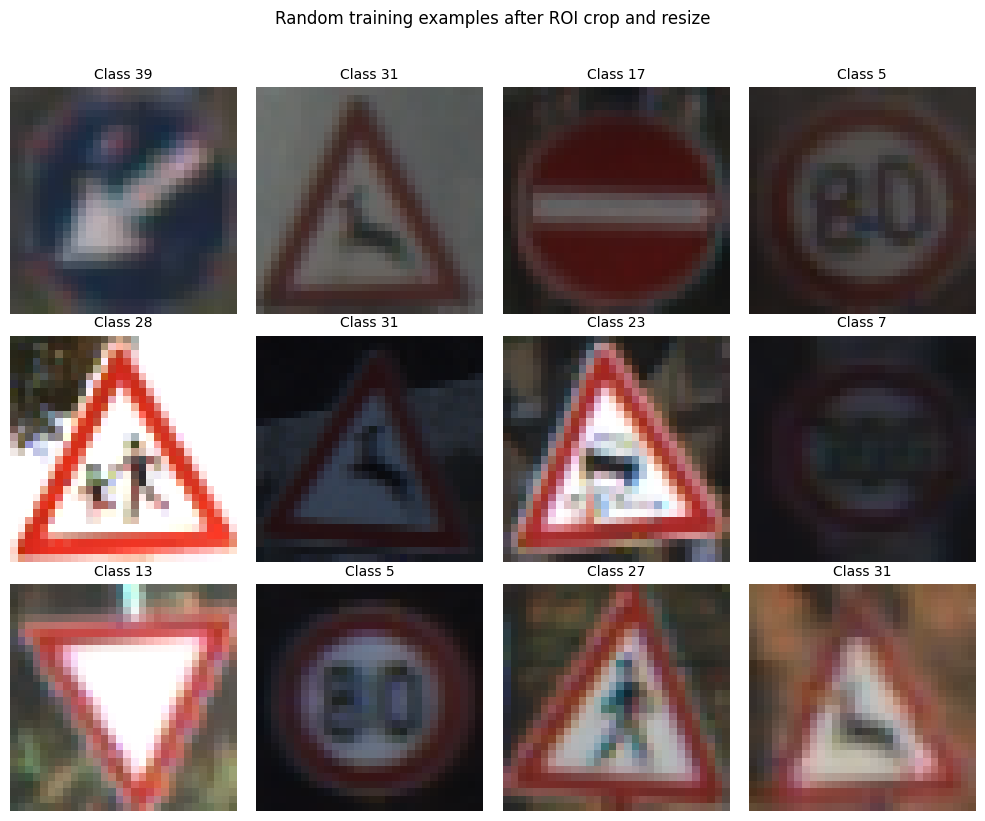

In [5]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_train), size=min(12, len(X_train)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(X_train[idx])
    ax.set_title(f'Class {y_train[idx]}', fontsize=10)
    ax.axis('off')
for ax in axes.flat[len(sample_indices):]:
    ax.axis('off')
fig.suptitle('Random training examples after ROI crop and resize', y=1.02)
plt.tight_layout()
plt.show()

### Normalize pixels and encode labels

The final layer uses a 43-way softmax, so labels are one-hot encoded for categorical cross-entropy. The original integer labels are retained separately for scikit-learn evaluation metrics.

In [6]:
from tensorflow.keras.utils import to_categorical
X_train = X_train.astype('float32') / 255.0
X_val = X_val.astype('float32') / 255.0

NUM_CLASSES = 43
y_train_onehot = to_categorical(y_train, NUM_CLASSES)
y_val_onehot = to_categorical(y_val, NUM_CLASSES)

print('Normalized train pixel range:', float(X_train.min()), 'to', float(X_train.max()))
print('Normalized validation pixel range:', float(X_val.min()), 'to', float(X_val.max()))
print('One-hot label shape:', y_train_onehot.shape)

Normalized train pixel range: 0.0 to 1.0
Normalized validation pixel range: 0.0 to 1.0
One-hot label shape: (31349, 43)


## 5. Training-only data augmentation

Small geometric changes are used to make training less sensitive to modest differences in position and viewpoint. Augmentation is applied **only to training batches**; validation images remain unchanged so that validation metrics are evaluated on a stable dataset.

Horizontal flipping is not enabled because mirrored traffic signs may be unrealistic or change sign meaning.

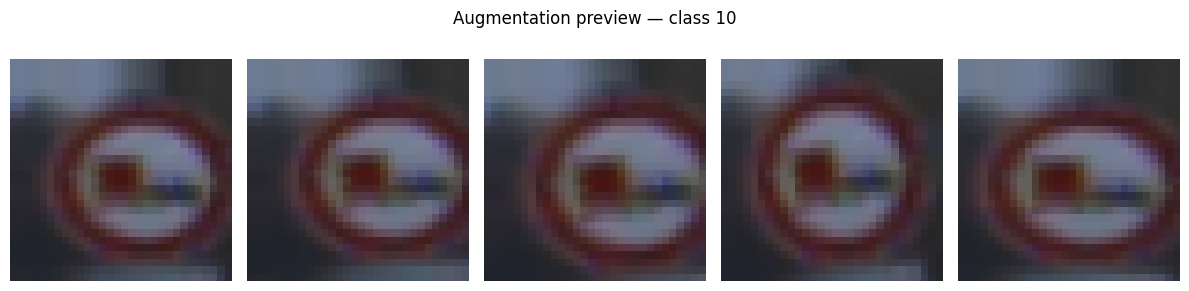

In [7]:
datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    horizontal_flip=False,
)

# Preview several augmented views of one training image.
preview_idx = int(rng.integers(0, len(X_train)))
preview_image = X_train[preview_idx:preview_idx + 1]
preview_generator = datagen.flow(
    preview_image,
    batch_size=1,
    shuffle=False,
    seed=SEED,
)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax in axes:
    augmented_image = next(preview_generator)[0]
    ax.imshow(np.clip(augmented_image, 0, 1))
    ax.axis('off')
fig.suptitle(f'Augmentation preview — class {y_train[preview_idx]}')
plt.tight_layout()
plt.show()

## 6. CNN architecture

The model progressively transforms pixels into more informative visual features:

- **Convolution layers** learn local patterns such as edges, borders, textures, and combinations of shapes.
- **Max pooling** reduces spatial resolution while retaining strong activations.
- **Dropout** randomly disables a fraction of activations during training to help reduce overfitting.
- **Dense layer** combines the extracted features for classification.
- **Softmax output** returns a probability distribution over 43 classes.

The architecture and learning rate below use a selected configuration from an earlier tuning run. This notebook documents and trains that configuration; it does not reproduce the hyperparameter search itself.

In [8]:
model = Sequential([
    Input(shape=X_train.shape[1:]),

    Conv2D(48, (5, 5), activation='relu'),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPool2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu'),
    Conv2D(384, (3, 3), activation='relu'),
    MaxPool2D((2, 2)),
    Dropout(0.20),

    Flatten(),

    Dense(256, activation='relu'),
    Dropout(0.4),

    Dense(43, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1791721019.490840     161 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791721019.495595     161 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 48)     │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        55,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 384)      │       442,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 384)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,573,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,233,579 (8.52 MB)

 Trainable params: 2,233,579 (8.52 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Model training

`EarlyStopping` monitors validation loss. If validation loss does not improve for five consecutive epochs, training stops and the weights from the best observed validation loss are restored.

Validation data is used for monitoring and model selection. It is not augmented. The official test set is not loaded until the final evaluation section.

In [9]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    datagen.flow(
        X_train,
        y_train_onehot,
        batch_size=128,
        shuffle=True
    ),
    epochs=40,
    validation_data=(X_val, y_val_onehot),
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/40
  3/245 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.0365 - loss: 3.7450 

I0000 00:00:1791721032.686637     237 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


245/245 ━━━━━━━━━━━━━━━━━━━━ 34s 97ms/step - accuracy: 0.4704 - loss: 1.8585 - val_accuracy: 0.8931 - val_loss: 0.3578
Epoch 2/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - accuracy: 0.8812 - loss: 0.3898 - val_accuracy: 0.9635 - val_loss: 0.1617
Epoch 3/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 16s 67ms/step - accuracy: 0.9442 - loss: 0.1881 - val_accuracy: 0.9668 - val_loss: 0.1315
Epoch 4/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - accuracy: 0.9667 - loss: 0.1134 - val_accuracy: 0.9756 - val_loss: 0.1166
Epoch 5/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 68ms/step - accuracy: 0.9732 - loss: 0.0888 - val_accuracy: 0.9746 - val_loss: 0.1047
Epoch 6/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 68ms/step - accuracy: 0.9797 - loss: 0.0717 - val_accuracy: 0.9777 - val_loss: 0.0964
Epoch 7/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 68ms/step - accuracy: 0.9823 - loss: 0.0624 - val_accuracy: 0.9772 - val_loss: 0.1033
Epoch 8/40
245/245 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - accuracy: 0.9853 - loss: 0.0534 - val_accurac

### Learning curves

The curves help diagnose whether the model is still learning, has converged, or shows signs of overfitting. Interpret training and validation curves together rather than judging by training accuracy alone.

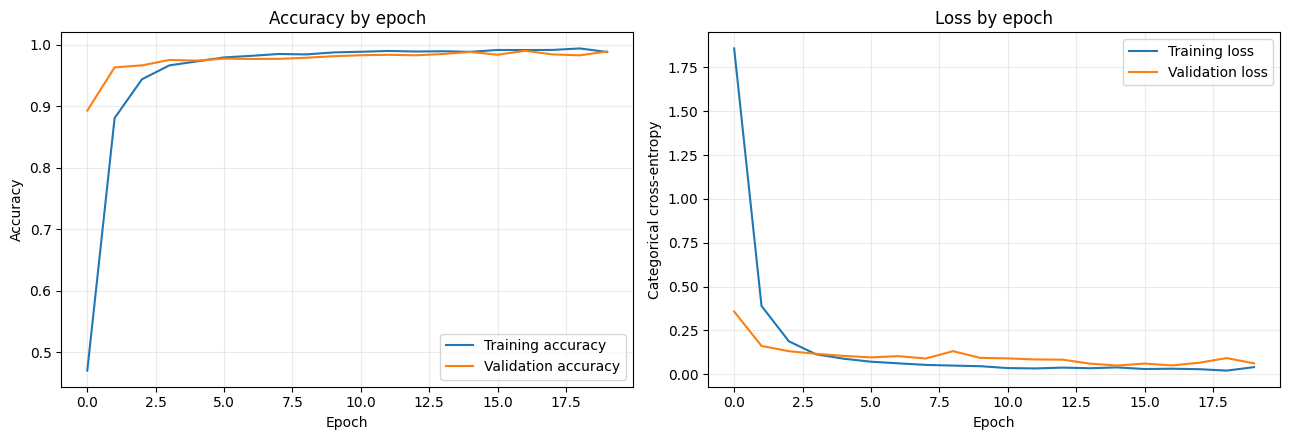

Best validation-loss epoch: 15
Epochs completed: 20


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history.history['accuracy'], label='Training accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Accuracy by epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history.history['loss'], label='Training loss')
axes[1].plot(history.history['val_loss'], label='Validation loss')
axes[1].set_title('Loss by epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Categorical cross-entropy')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

best_epoch = int(np.argmin(history.history['val_loss']) + 1)
print(f'Best validation-loss epoch: {best_epoch}')
print(f'Epochs completed: {len(history.history["loss"])}')

## 8. Validation evaluation

Accuracy is the fraction of correctly classified images. Because classes are not equally represented, **macro precision, macro recall, and macro F1** are also reported; these calculate the metric for each class and then give each class equal weight.

The classification report reveals per-class precision, recall, F1-score, and support. The report must be called as `classification_report(y_true, y_pred)`.

In [11]:
y_true_val = y_val.copy()  # integer labels retained from image loading
val_probabilities = model.predict(X_val, batch_size=BATCH_SIZE, verbose=1)
pred_val = np.argmax(val_probabilities, axis=1)

validation_metrics = {
    'accuracy': accuracy_score(y_true_val, pred_val),
    'macro_precision': precision_score(y_true_val, pred_val, average='macro', zero_division=0),
    'macro_recall': recall_score(y_true_val, pred_val, average='macro', zero_division=0),
    'macro_f1': f1_score(y_true_val, pred_val, average='macro', zero_division=0),
}

print('Validation metrics')
for metric_name, value in validation_metrics.items():
    print(f'{metric_name:>16}: {value:.4f} ({value:.2%})')

val_report = classification_report(
    y_true_val,
    pred_val,
    labels=np.arange(NUM_CLASSES),
    output_dict=True,
    zero_division=0,
)
report_accuracy = val_report.pop('accuracy', None)   # scalar, not a dict
val_report_df = pd.DataFrame.from_dict(val_report, orient='index')

print('\nPer-class validation report:')
display(val_report_df.round(3))
if report_accuracy is not None:
    print(f'Overall accuracy: {report_accuracy:.4f}')

62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
Validation metrics
        accuracy: 0.9885 (98.85%)
 macro_precision: 0.9872 (98.72%)
    macro_recall: 0.9846 (98.46%)
        macro_f1: 0.9854 (98.54%)

Per-class validation report:


,precision,recall,f1-score,support
0,1.000,0.978,0.989,90.0
1,0.997,0.997,0.997,390.0
2,0.987,1.000,0.993,450.0
3,1.000,1.000,1.000,300.0
4,0.998,1.000,0.999,420.0
5,0.983,0.989,0.986,360.0
6,1.000,1.000,1.000,90.0
7,0.993,0.993,0.993,270.0
8,0.993,1.000,0.996,270.0
9,0.985,1.000,0.993,270.0


Overall accuracy: 0.9885


### Which classes need attention?

Sort classes by validation F1-score to identify the least reliable categories. Low F1 can reflect visually similar signs, limited examples, difficult images, or a combination of factors; the score alone does not prove the cause.

10 classes with the lowest validation F1-score:


,class_id,precision,recall,f1_score,support
21,21,0.904,0.783,0.839,60.0
40,40,1.000,0.856,0.922,90.0
31,31,0.877,1.000,0.935,150.0
34,34,1.000,0.911,0.953,90.0
38,38,1.000,0.923,0.960,390.0
20,20,0.991,0.942,0.966,120.0
41,41,0.938,1.000,0.968,30.0
12,12,0.949,1.000,0.974,390.0
15,15,0.952,1.000,0.976,120.0
27,27,0.968,1.000,0.984,30.0


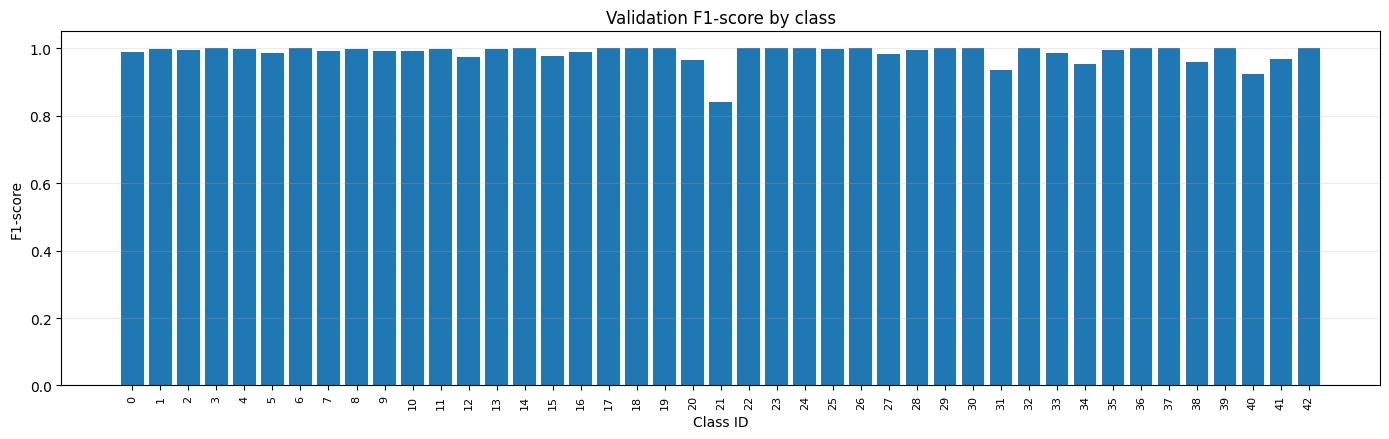

In [13]:
per_class_metrics = pd.DataFrame({
    'class_id': np.arange(NUM_CLASSES),
    'precision': [val_report[str(i)]['precision'] for i in range(NUM_CLASSES)],
    'recall': [val_report[str(i)]['recall'] for i in range(NUM_CLASSES)],
    'f1_score': [val_report[str(i)]['f1-score'] for i in range(NUM_CLASSES)],
    'support': [val_report[str(i)]['support'] for i in range(NUM_CLASSES)],
})

print('10 classes with the lowest validation F1-score:')
display(per_class_metrics.sort_values('f1_score').head(10).round(3))

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(per_class_metrics['class_id'].astype(str), per_class_metrics['f1_score'])
ax.set_title('Validation F1-score by class')
ax.set_xlabel('Class ID')
ax.set_ylabel('F1-score')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', labelrotation=90, labelsize=8)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### Inspect individual validation errors

Looking at mistakes can reveal whether errors cluster around visually similar signs, very small/blurred signs, poor crops, or unusual lighting. These examples are useful starting points for analysis, not a substitute for systematic evaluation.

Misclassified validation images: 90 / 7,860


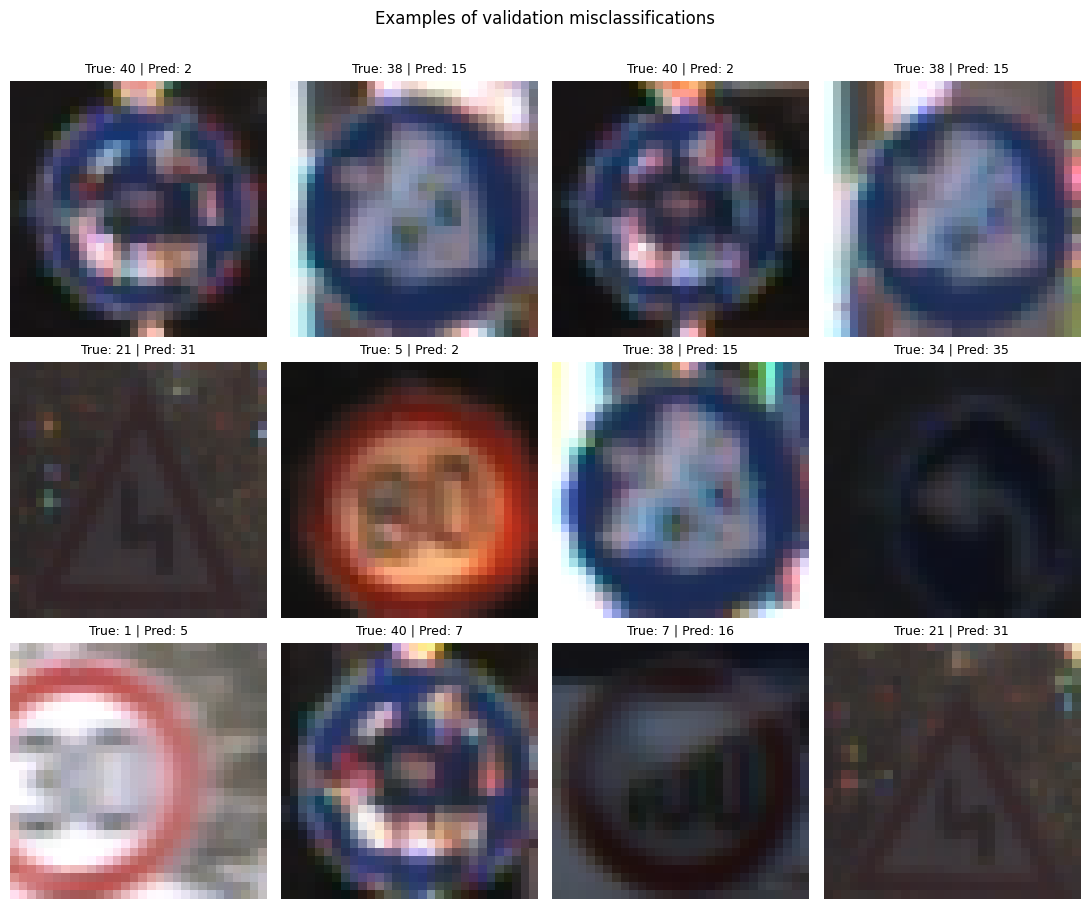

In [14]:
misclassified_indices = np.flatnonzero(pred_val != y_true_val)
print(f'Misclassified validation images: {len(misclassified_indices):,} / {len(y_true_val):,}')

if len(misclassified_indices) > 0:
    display_indices = rng.choice(
        misclassified_indices,
        size=min(12, len(misclassified_indices)),
        replace=False,
    )
    fig, axes = plt.subplots(3, 4, figsize=(11, 9))
    for ax, idx in zip(axes.flat, display_indices):
        ax.imshow(np.clip(X_val[idx], 0, 1))
        ax.set_title(f'True: {y_true_val[idx]} | Pred: {pred_val[idx]}', fontsize=9)
        ax.axis('off')
    for ax in axes.flat[len(display_indices):]:
        ax.axis('off')
    fig.suptitle('Examples of validation misclassifications', y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print('No validation misclassifications were found in this run.')

## 9. Official test-set evaluation

The official test set is loaded **after** model training and validation analysis. Do not use these test metrics to choose architecture, tune hyperparameters, or make repeated modeling decisions; those decisions should be made using training and validation data.

Test preprocessing is intentionally identical to training/validation preprocessing, including RGB conversion, ROI cropping, resizing, and pixel normalization.

In [19]:
import cv2
import numpy as np
from tqdm import tqdm

IMG_SIZE = 30          # common choice for GTSRB; change if your model needs a different input size
BASE_PATH = '/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign' # or '/kaggle/input/gtsrb-german-traffic-sign' if you're on Kaggle

test = pd.read_csv(BASE_PATH + '/Test.csv')
def load_data(df, base_path, img_size=IMG_SIZE, use_roi=True):
    images = []
    labels = []
    
    for _, row in tqdm(df.iterrows(), total=len(df)):
        img_path = os.path.join(base_path, row['Path'])
        img = cv2.imread(img_path)
        
        if img is None:
            print("Warning: couldn't read", img_path)
            continue
        
        # BGR -> RGB (cv2 loads as BGR by default)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Crop to ROI (the sign only, no background margin)
        if use_roi:
            x1, y1, x2, y2 = row['Roi.X1'], row['Roi.Y1'], row['Roi.X2'], row['Roi.Y2']
            img = img[y1:y2, x1:x2]
        
        # Resize to fixed size
        img = cv2.resize(img, (img_size, img_size))
        
        images.append(img)
        labels.append(row['ClassId'])
    
    X = np.array(images)
    y = np.array(labels)
    return X, y

# Build train and val arrays
X_test, y_test = load_data(test, BASE_PATH)

print("X_test:", X_test.shape)   # (num_train, 30, 30, 3)
print("y_test:", y_test.shape)   # (num_train,)


100%|██████████| 12630/12630 [00:53<00:00, 237.39it/s]

X_test: (12630, 30, 30, 3)
y_test: (12630,)


In [20]:
X_test = X_test.astype('float32') / 255.0

In [21]:
test_probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
pred_test = np.argmax(test_probabilities, axis=1)

test_metrics = {
    'accuracy': accuracy_score(y_test, pred_test),
    'macro_precision': precision_score(y_test, pred_test, average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, pred_test, average='macro', zero_division=0),
    'macro_f1': f1_score(y_test, pred_test, average='macro', zero_division=0),
}

print('Official test metrics')
for metric_name, value in test_metrics.items():
    print(f'{metric_name:>16}: {value:.4f} ({value:.2%})')

print('\nOfficial test classification report:')
print(classification_report(
    y_test,
    pred_test,
    labels=np.arange(NUM_CLASSES),
    zero_division=0,
))

99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Official test metrics
        accuracy: 0.9855 (98.55%)
 macro_precision: 0.9721 (97.21%)
    macro_recall: 0.9795 (97.95%)
        macro_f1: 0.9750 (97.50%)

Official test classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       0.99      1.00      1.00       720
           2       0.99      1.00      0.99       750
           3       0.99      0.99      0.99       450
           4       1.00      0.99      0.99       660
           5       0.99      0.97      0.98       630
           6       0.99      1.00      1.00       150
           7       1.00      1.00      1.00       450
           8       0.99      1.00      0.99       450
           9       1.00      1.00      1.00       480
          10       1.00      0.98      0.99       660
          11       0.98      1.00      0.99       420
          12       1.00      0.98      0.99       690
        

## 10. Results summary

The table below consolidates validation and official test metrics generated in this run. Differences between the two splits are expected: validation is used for model monitoring, while the official test set provides a final check on unseen benchmark examples.

In [22]:
results_summary = pd.DataFrame([
    {'split': 'Validation', **validation_metrics},
    {'split': 'Official test', **test_metrics},
])

styled_results = results_summary.style.format({
    'accuracy': '{:.2%}',
    'macro_precision': '{:.2%}',
    'macro_recall': '{:.2%}',
    'macro_f1': '{:.2%}',
})
display(styled_results)

,split,accuracy,macro_precision,macro_recall,macro_f1
0,Validation,98.85%,98.72%,98.46%,98.54%
1,Official test,98.55%,97.21%,97.95%,97.50%
